# Actividad 2 — K-means (Notebook 1: avance manual)
**Asignatura:** Inteligencia Artificial I  
**Grupo:** 5  
**Estado:** Avance funcional para asesoría; **no es la entrega final**.

**Qué sí hace:** crea datos, calcula distancias, forma grupos con K-means programado desde cero y muestra un gráfico.  
**Qué falta:** validación frente a scikit-learn, análisis adicional y conclusiones finales.

> Para esta implementación manual se usa **NumPy** y **Matplotlib**. No se utilizan funciones de aprendizaje automático de librerías especializadas.

## 1. Introducción
K-means es un algoritmo **no supervisado**: agrupa observaciones que se parecen entre sí sin necesidad de etiquetas previas.

En este ejemplo trabajaremos con **15 puntos de dos variables** y pediremos **K = 3 grupos**. Son datos inventados para entender el procedimiento, no representan un estudio real.

## 2. Fórmulas básicas
**Distancia euclidiana:** decide qué centroide queda más cerca de un punto.

$$d(x,\mu_j)=\sqrt{\sum_{i=1}^{p}(x_i-\mu_{ji})^2}$$

**Actualización del centroide:** promedio de los puntos asignados al grupo.

$$\mu_j=\frac{1}{|C_j|}\sum_{x\in C_j}x$$

**Idea:** elegir centroides iniciales → asignar puntos al más cercano → recalcular centroides → repetir hasta estabilizar.

## 3. Datos e importaciones
Los datos se preparan manualmente. Los tres centroides iniciales se seleccionan como puntos de diferentes zonas para facilitar esta primera demostración.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Datos sintéticos: 15 observaciones con dos características
X = np.array([
    [1.0, 1.0], [1.2, 1.4], [1.4, 0.8], [0.8, 1.3], [1.6, 1.1],
    [5.0, 5.0], [5.4, 4.7], [4.8, 5.1], [5.2, 5.5], [4.6, 4.8],
    [8.2, 1.0], [8.0, 1.5], [8.8, 1.3], [8.4, 0.7], [7.7, 0.9]
], dtype=float)

k = 3
print('Número de datos:', len(X))
print('Número de grupos (K):', k)
print('Primeros puntos:\n', X[:5])

Número de datos: 15
Número de grupos (K): 3
Primeros puntos:
 [[1.  1. ]
 [1.2 1.4]
 [1.4 0.8]
 [0.8 1.3]
 [1.6 1.1]]


## 4. Implementación de K-means desde cero
Este código no llama a `KMeans` de scikit-learn: implementa directamente la asignación por distancia euclidiana y la actualización de centroides.

In [2]:
def kmeans_manual(datos, centroides_iniciales, max_iter=100):
    centroides = centroides_iniciales.astype(float).copy()
    k = len(centroides)

    for iteracion in range(1, max_iter + 1):
        # Distancia euclidiana de cada dato a cada centroide
        distancias = np.sqrt(
            np.sum((datos[:, None, :] - centroides[None, :, :]) ** 2, axis=2)
        )

        # El grupo elegido es el del centroide más cercano
        grupos = np.argmin(distancias, axis=1)

        # Cada centroide pasa a ser el promedio de su grupo
        nuevos_centroides = np.array([
            datos[grupos == j].mean(axis=0) if np.any(grupos == j)
            else centroides[j]  # Se conserva si el grupo quedó vacío
            for j in range(k)
        ])

        if np.allclose(nuevos_centroides, centroides):
            centroides = nuevos_centroides
            break
        centroides = nuevos_centroides

    return grupos, centroides, iteracion

centroides_iniciales = X[[0, 5, 10]]
grupos, centroides, iteraciones = kmeans_manual(X, centroides_iniciales)

print('Iteraciones realizadas:', iteraciones)
print('Centroides finales:\n', np.round(centroides, 2))
print('Grupos asignados:', grupos)
print('Cantidad de puntos por grupo:', np.bincount(grupos, minlength=k))

Iteraciones realizadas: 2
Centroides finales:
 [[1.2  1.12]
 [5.   5.02]
 [8.22 1.08]]
Grupos asignados: [0 0 0 0 0 1 1 1 1 1 2 2 2 2 2]
Cantidad de puntos por grupo: [5 5 5]


## 5. Visualización de los resultados
Cada color corresponde a un grupo asignado por el algoritmo. Las **X rojas** son los centroides finales.

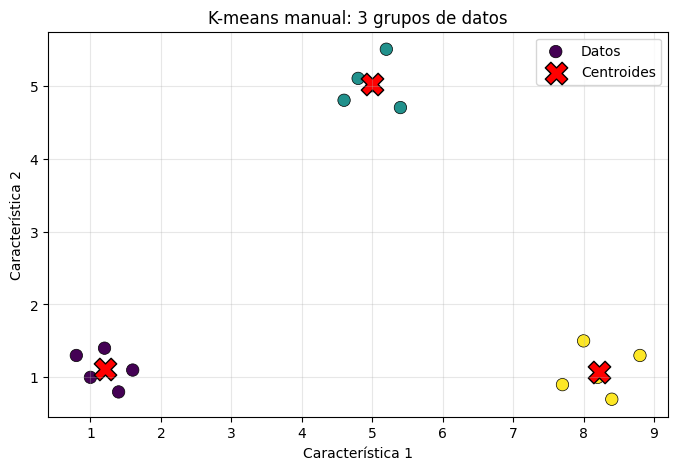

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=grupos, cmap='viridis', s=80,
            edgecolors='black', linewidths=0.5, label='Datos')
plt.scatter(centroides[:, 0], centroides[:, 1], color='red',
            marker='X', s=260, edgecolors='black', label='Centroides')
plt.title('K-means manual: 3 grupos de datos')
plt.xlabel('Característica 1')
plt.ylabel('Característica 2')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Comentario preliminar para exponer
En esta prueba, el algoritmo dividió los 15 puntos en tres grupos. Primero calculó la distancia a los centroides, luego asignó cada dato al centroide más cercano y finalmente recalculó el promedio de los puntos de cada grupo.

Esto demuestra el **funcionamiento básico de K-means programado manualmente**, pero todavía no demuestra cuál K sería el ideal para un problema real.

## 7. Pendiente para próximas versiones (no implementado todavía)
- [ ] Comparar esta implementación con `sklearn.cluster.KMeans`.
- [ ] Probar otros centroides iniciales y analizar su efecto.
- [ ] Añadir pseudocódigo formal y conclusiones finales.
- [ ] Completar las referencias en formato IEEE.

**Próximo commit sugerido:** `Validación de K-means manual frente a scikit-learn`.